# Mission — Pilote automatique de l'atterrisseur lunaire Eagle-1

**AstroDynamics · R&D** — Ingénieur ML junior, apprentissage par renforcement.

Objectif : un pilote automatique qui pose **Eagle-1** en douceur sur la zone cible, avec précision et peu de
carburant, dans la simulation Gymnasium **LunarLander-v3**.

| Critère du cahier des charges | Où le vérifier |
|---|---|
| Récompense moyenne **≥ 200 sur 100 épisodes**, stable (écart-type faible) | §6 |
| Exploration de l'environnement et baseline par défaut (≥ 50 épisodes) | §1 et §3 |
| Choix argumenté de l'algorithme | §2 |
| Optimisation des hyperparamètres, **un à la fois**, documentée, suivie sous TensorBoard | §4 |
| Généralisation (pas de surapprentissage) | §6 |
| Vidéo de 20-30 s (`RecordVideo`) | §7 |
| API, GUI, tableau de bord (logique RL côté API) | §8 |

> Le brief cite `LunarLander-v2` : cette version a été retirée de Gymnasium 1.x et remplacée par **v3**
> (même tâche, corrections de bugs). Nous utilisons donc `LunarLander-v3`.

Le code réutilisable est dans le package [`eagle1/`](../eagle1) ; ce notebook présente la démarche et les résultats.

In [1]:
import sys, json
sys.path.insert(0, "..")

import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Video, display

from eagle1.core import ACTIONS, OBS_NAMES, RESULTS, MEDIA, make_env, load_model, load_experiments, play_episode
from eagle1.train import EXPERIMENTS, run, promote

pd.set_option("display.precision", 1)
import warnings; warnings.filterwarnings("ignore", category=DeprecationWarning)


def show(df):
    # pourcentages lisibles pour les colonnes de taux
    rates = {c: "{:.0%}" for c in df.columns if "success" in c}
    return df.style.format(precision=1, formatter=rates)
plt.rcParams["figure.dpi"] = 100

## 1. Exploration de l'environnement

### Espaces d'observation et d'action

Observation : Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Action      : Discrete(4)
Durée max   : 1000 pas (50 pas = 1 s)


variable,x,y,vx,vy,angle,vitesse_angulaire,jambe_gauche,jambe_droite
valeur initiale,6.0e-03,1.4,0.6,-0.5,-7.0e-03,-0.1,0.0,0.0


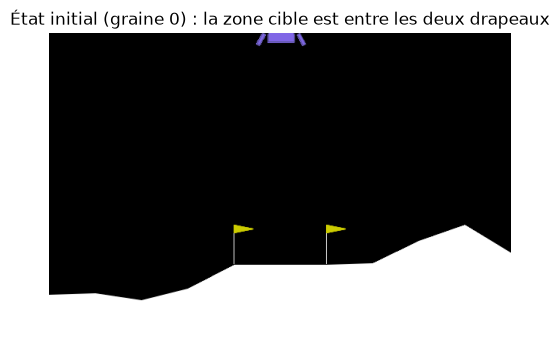

In [2]:
env = make_env(render_mode="rgb_array")
print("Observation :", env.observation_space)
print("Action      :", env.action_space)
print("Durée max   :", env.spec.max_episode_steps, "pas (50 pas = 1 s)")

obs, _ = env.reset(seed=0)
display(pd.DataFrame({"variable": OBS_NAMES, "valeur initiale": obs.round(3)}).set_index("variable").T)
plt.figure(figsize=(6, 4)); plt.imshow(env.render()); plt.axis("off")
plt.title("État initial (graine 0) : la zone cible est entre les deux drapeaux"); plt.show()

| Observation (Box, 8 réels) | Sens |
|---|---|
| `x`, `y` | position (la cible est en (0, 0)) |
| `vx`, `vy` | vitesses horizontale et verticale |
| `angle`, `vitesse_angulaire` | orientation du module |
| `jambe_gauche`, `jambe_droite` | 1 si la jambe touche le sol |

| Action (Discrete(4)) | Effet |
|---|---|
| 0 | ne rien faire |
| 1 | moteur d'orientation gauche |
| 2 | moteur principal |
| 3 | moteur d'orientation droit |

**Récompense** (façonnée, à chaque pas) : se rapprocher de la cible, ralentir et rester droit rapportent ;
chaque jambe au contact du sol rapporte +10 ; le moteur principal coûte 0.3 par pas, un moteur latéral 0.03
→ la consommation de carburant est **directement pénalisée**. Fin d'épisode : **+100** si le module se pose et
s'immobilise, **−100** s'il s'écrase ou sort de l'écran. Un épisode à **≥ 200** est considéré comme réussi.

### Agent aléatoire : le point zéro

In [3]:
random_env = make_env()
random_env.action_space.seed(0)
random_rewards = []
for i in range(50):
    obs, _ = random_env.reset(seed=i)
    done, total = False, 0.0
    while not done:
        obs, r, term, trunc, _ = random_env.step(random_env.action_space.sample())
        total += r; done = term or trunc
    random_rewards.append(total)
print(f"Agent aléatoire sur 50 épisodes : {np.mean(random_rewards):.1f} ± {np.std(random_rewards):.1f}")

Agent aléatoire sur 50 épisodes : -210.2 ± 125.3


L'agent aléatoire s'écrase systématiquement (≈ −210) : il faut gagner environ **+410 points** pour passer le seuil de 200.

## 2. Choix de l'algorithme

L'espace d'actions est **discret** (4 actions) et l'espace d'états **continu** (8 réels) : pas de Q-table possible
(exercice 2), il faut un approximateur de fonction.

| | **DQN** (off-policy, basé valeur) | **PPO** (on-policy, policy gradient) |
|---|---|---|
| Actions | discrètes uniquement ✅ | discrètes et continues ✅ |
| Données | replay buffer : réutilise chaque transition → économe en interactions | jette les données après chaque mise à jour → plus d'interactions |
| Stabilité | sensible aux hyperparamètres (target network, exploration) | mises à jour bornées (*clipping*) → très stable |
| Parallélisme | 1 environnement en pratique | N environnements en parallèle → rapide en temps réel |

Le brief recommande **DQN** pour les actions discrètes et cite **PPO** comme alternative plus optimisée :
nous entraînons **les deux** avec leurs paramètres par défaut, puis nous optimisons et retenons le plus performant.

## 3. Pipeline d'entraînement et baselines

Toutes les expériences sont déclarées dans [`eagle1/train.py`](../eagle1/train.py). Pour chacune :
entraînement (journaux TensorBoard dans `logs/mission`), évaluation périodique de 10 épisodes (courbe
d'apprentissage), puis **évaluation finale sur 100 épisodes aux graines jamais vues** (≥ 50 demandés).

Lancement dans le container (≈ 1 h 30 pour tout, 15 expériences en parallèle) :
```
docker compose exec jupyter uv run --no-sync python -m eagle1.train --workers 15
```
Les résultats étant sauvegardés dans `results/`, ce notebook les relit. Passer `RETRAIN = True` pour tout réentraîner.

In [4]:
RETRAIN = False
if RETRAIN:
    for exp in EXPERIMENTS:
        run(exp)

experiments = load_experiments().set_index("name")
pd.DataFrame([(e.round, e.name, e.algo, e.changed, e.timesteps, e.n_envs) for e in EXPERIMENTS],
             columns=["étape", "expérience", "algo", "changement", "pas", "envs"]).set_index("expérience")

,étape,algo,changement,pas,envs
expérience,,,,,
dqn_baseline,1,DQN,défaut SB3,300000,1
ppo_baseline,1,PPO,défaut SB3,1000000,8
dqn_buffer_50k,1,DQN,buffer_size=50 000,300000,1
dqn_lr_6e-4,1,DQN,learning_rate=6.3e-4,300000,1
dqn_target_250,1,DQN,target_update_interval=250,300000,1
dqn_tuned,1,DQN,combinaison RL Zoo,300000,1
ppo_gamma_0.999,1,PPO,gamma=0.999,1000000,8
ppo_nsteps_1024,1,PPO,n_steps=1024,1000000,8
ppo_lr_1e-3,1,PPO,learning_rate=1e-3,1000000,8


,algo,changed,timesteps,mean_reward,std_reward,success_rate,train_minutes
name,,,,,,,
dqn_baseline,DQN,défaut SB3,300000,-63.0,55.8,0%,24.9
ppo_baseline,PPO,défaut SB3,1000000,222.2,72.6,88%,39.1


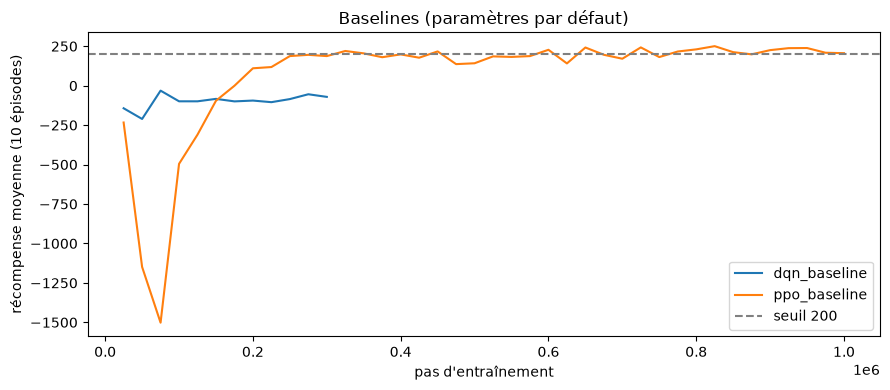

In [5]:
def curve(name):
    d = np.load(RESULTS / "curves" / name / "evaluations.npz")
    return d["timesteps"], d["results"].mean(axis=1)

cols = ["algo", "changed", "timesteps", "mean_reward", "std_reward", "success_rate", "train_minutes"]
display(show(experiments.loc[["dqn_baseline", "ppo_baseline"], cols]))

plt.figure(figsize=(9, 4))
for name in ["dqn_baseline", "ppo_baseline"]:
    plt.plot(*curve(name), label=name)
plt.axhline(200, ls="--", c="gray", label="seuil 200")
plt.xlabel("pas d'entraînement"); plt.ylabel("récompense moyenne (10 épisodes)")
plt.title("Baselines (paramètres par défaut)"); plt.legend(); plt.tight_layout(); plt.show()

**Analyse des baselines.**

- **DQN par défaut échoue** (≈ −63) : ses épisodes durent presque 1 000 pas, la limite de temps. L'agent a appris
  à **planer** pour éviter le −100 du crash, sans jamais oser se poser — un optimum local classique. Les réglages
  par défaut de SB3 (target network mis à jour tous les 10 000 pas, buffer d'un million de transitions) sont
  pensés pour Atari, pas pour ce problème.
- **PPO par défaut passe déjà le seuil** (≈ 222) mais avec un écart-type élevé (≈ 73) : certains épisodes
  échouent. Le critère demande une moyenne **stable** : il reste du travail.

Le pipeline fonctionne de bout en bout (entraînement → évaluation sur 100 épisodes → sauvegarde), ce qui était
l'objectif de cette étape.

## 4. Optimisation des hyperparamètres

Méthode : partir de la baseline et **ne changer qu'un seul hyperparamètre à la fois** pour isoler son effet.
Chaque ligne est comparée à sa référence (Δ). Les courbes sont aussi consultables dans **TensorBoard**
(`http://localhost:6006`, onglet *Scalars*, `rollout/ep_rew_mean` et `eval/mean_reward`).

In [6]:
def compare(prefix, ref):
    df = experiments[experiments.index.str.startswith(prefix) & (experiments["round"] == 1)][cols].copy()
    df["Δ vs baseline"] = df["mean_reward"] - experiments.loc[ref, "mean_reward"]
    return df.sort_values("mean_reward", ascending=False)

display(show(compare("dqn", "dqn_baseline")))
display(show(compare("ppo", "ppo_baseline")))

,algo,changed,timesteps,mean_reward,std_reward,success_rate,train_minutes,Δ vs baseline
name,,,,,,,,
dqn_tuned,DQN,combinaison RL Zoo,300000,267.7,38.2,95%,44.1,330.7
dqn_buffer_50k,DQN,buffer_size=50 000,300000,84.3,115.4,14%,23.3,147.3
dqn_lr_6e-4,DQN,learning_rate=6.3e-4,300000,-0.4,100.3,3%,25.0,62.6
dqn_target_250,DQN,target_update_interval=250,300000,-51.7,26.2,0%,20.9,11.4
dqn_baseline,DQN,défaut SB3,300000,-63.0,55.8,0%,24.9,0.0


,algo,changed,timesteps,mean_reward,std_reward,success_rate,train_minutes,Δ vs baseline
name,,,,,,,,
ppo_lr_1e-3,PPO,learning_rate=1e-3,1000000,280.5,18.2,100%,35.9,58.3
ppo_ent_0.01,PPO,ent_coef=0.01,1000000,273.2,36.2,94%,34.4,51.0
ppo_gamma_0.999,PPO,gamma=0.999,1000000,272.2,26.8,98%,33.5,50.0
ppo_gae_0.98,PPO,gae_lambda=0.98,1000000,267.1,34.6,95%,36.6,44.8
ppo_baseline,PPO,défaut SB3,1000000,222.2,72.6,88%,39.1,0.0
ppo_nsteps_1024,PPO,n_steps=1024,1000000,190.6,95.9,77%,40.1,-31.6
ppo_epochs_4,PPO,n_epochs=4,1000000,176.6,84.8,67%,41.8,-45.6


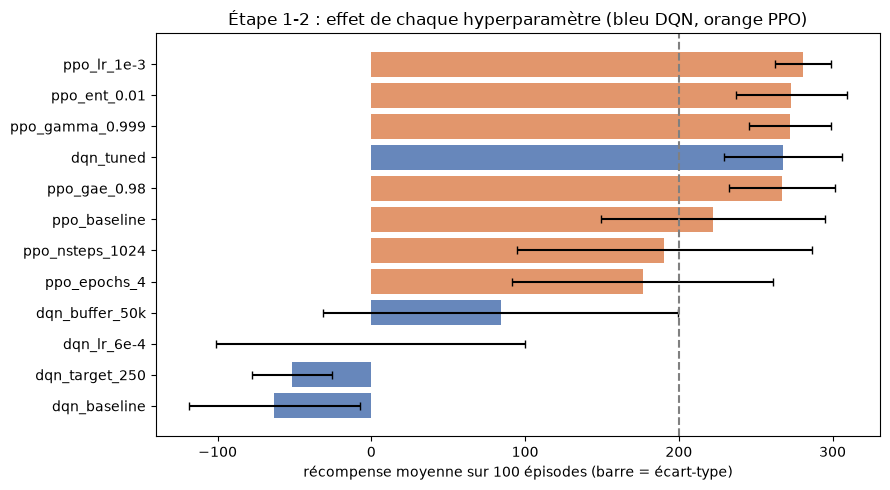

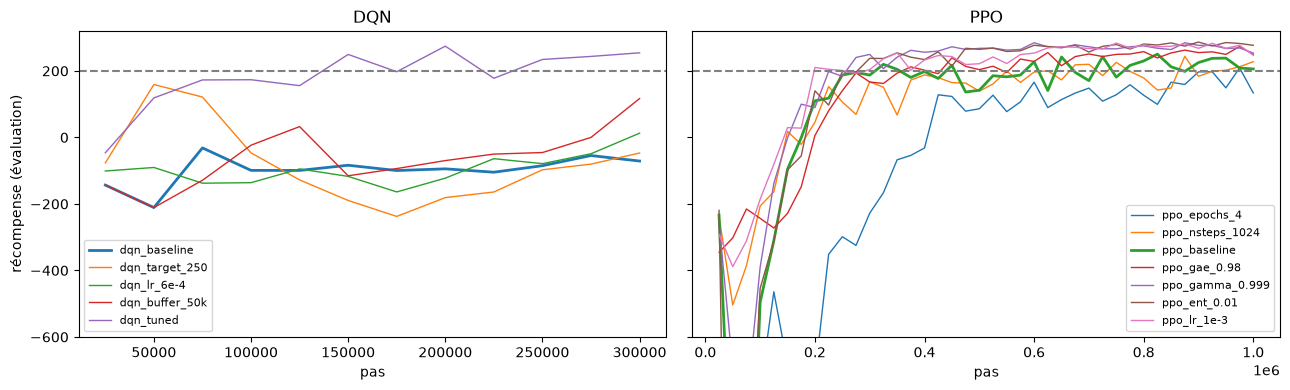

In [7]:
r1 = experiments[experiments["round"] == 1].sort_values("mean_reward")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(r1.index, r1["mean_reward"], xerr=r1["std_reward"], color=r1["algo"].map({"DQN": "#4C72B0", "PPO": "#DD8452"}),
        capsize=3, alpha=0.85)
ax.axvline(200, ls="--", c="gray")
ax.set_xlabel("récompense moyenne sur 100 épisodes (barre = écart-type)")
ax.set_title("Étape 1-2 : effet de chaque hyperparamètre (bleu DQN, orange PPO)")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, prefix in zip(axes, ["dqn", "ppo"]):
    for name in r1.index[r1.index.str.startswith(prefix)]:
        ax.plot(*curve(name), label=name, lw=2 if "baseline" in name else 1)
    ax.axhline(200, ls="--", c="gray"); ax.set_title(prefix.upper()); ax.set_xlabel("pas")
    ax.legend(fontsize=8)
axes[0].set_ylabel("récompense (évaluation)"); axes[0].set_ylim(-600, 320)
plt.tight_layout(); plt.show()

**Analyse de l'optimisation (un hyperparamètre à la fois).**

*PPO* — quatre changements isolés améliorent nettement la baseline et réduisent l'écart-type :

| Changement | Effet | Pourquoi |
|---|---|---|
| `learning_rate` 3e-4 → 1e-3 | ≈ 280 ± 18, meilleur changement isolé | apprend plus vite dans le budget d'1 M de pas |
| `gamma` 0.99 → 0.999 | ≈ 272 | le bonus +100 de l'atterrissage arrive tard : il faut valoriser le futur lointain |
| `ent_coef` 0 → 0.01 | ≈ 273 | bonus d'entropie : l'exploration dure plus longtemps, moins de convergence prématurée |
| `gae_lambda` 0.95 → 0.98 | ≈ 267 | estimation de l'avantage moins biaisée sur un horizon plus long |
| `n_steps` 2048 → 1024 | ≈ 191 (pire) | avec 8 environnements, lots deux fois plus petits → gradients plus bruités |
| `n_epochs` 10 → 4 | ≈ 177 (pire) | moins de passes par lot → apprentissage plus lent à budget égal |

*DQN* — réduire `buffer_size` à 50 000 aide (≈ 84, on oublie plus vite les transitions d'une politique
médiocre), `learning_rate` et `target_update_interval` seuls ne suffisent pas. Il faut la **combinaison RL Zoo**
(réseau 256×256, target tous les 250 pas, `train_freq` 4, `gradient_steps` -1…) pour atteindre ≈ 268.
DQN *peut* réussir, mais il est beaucoup plus sensible aux réglages que PPO.

➡️ **PPO est retenu** : meilleur score, plus stable, moins dépendant d'un réglage fin.

### Configuration finale

On combine les changements bénéfiques et on allonge l'entraînement (2 M de pas, 16 environnements).
Pour vérifier que le résultat n'est pas un coup de chance, la même configuration est entraînée avec
**3 graines différentes**.

,algo,changed,timesteps,mean_reward,std_reward,success_rate,train_minutes,min_reward
name,,,,,,,,
ppo_final_s0,PPO,combinaison finale,2000000,280.5,19.3,100%,45.7,242.3
ppo_final_s1,PPO,combinaison finale,2000000,282.3,20.5,100%,45.9,228.4
ppo_final_s2,PPO,combinaison finale,2000000,278.4,20.2,100%,46.9,228.3


Moyenne des 3 graines : 280.4 (écart entre graines : 1.6)
Hyperparamètres : {"n_steps": 1024, "batch_size": 64, "n_epochs": 4, "gamma": 0.999, "gae_lambda": 0.98, "ent_coef": 0.01}


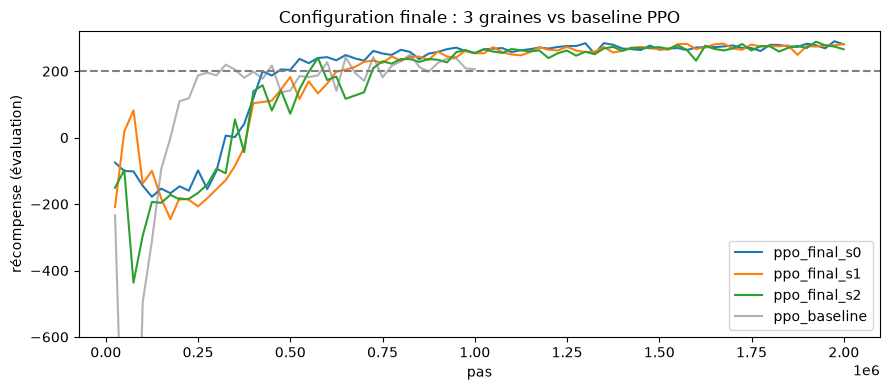

In [8]:
finals = experiments[experiments["round"] == 2]
display(show(finals[cols + ["min_reward"]]))
print(f"Moyenne des 3 graines : {finals['mean_reward'].mean():.1f} "
      f"(écart entre graines : {finals['mean_reward'].std(ddof=0):.1f})")
print("Hyperparamètres :", finals["params"].iloc[0])

plt.figure(figsize=(9, 4))
for name in finals.index:
    plt.plot(*curve(name), label=name)
plt.plot(*curve("ppo_baseline"), label="ppo_baseline", c="gray", alpha=0.6)
plt.axhline(200, ls="--", c="gray")
plt.xlabel("pas"); plt.ylabel("récompense (évaluation)"); plt.ylim(-600, 320)
plt.title("Configuration finale : 3 graines vs baseline PPO"); plt.legend(); plt.tight_layout(); plt.show()

**Analyse de la configuration finale.** Les trois graines donnent ≈ 278-282 avec un écart-type ≈ 20 et
**100 % d'épisodes au-dessus de 200** : le résultat est reproductible, ce n'est pas un coup de chance.

Remarque : `n_steps=1024` et `n_epochs=4` dégradaient le score *isolément*. Ils ne nuisent plus ici car le
nombre d'environnements passe à 16 (lots de 1024 × 16 = 16 384 transitions, comme la baseline) et le budget
double (2 M de pas). Un effet d'hyperparamètre dépend du reste de la configuration : c'est pourquoi on valide
la combinaison finale par une nouvelle expérience, et non par addition des gains.

Choix du modèle de production : **`ppo_final_s0`**, dont le **pire épisode est le meilleur des trois** (≈ 242).
Pour un atterrisseur, le pire cas compte plus que quelques dixièmes de moyenne.

## 5. Modèle retenu

Le meilleur des trois entraînements finaux est promu en modèle de production `models/eagle1_best.zip`
(`python -m eagle1.train --promote <nom>`), utilisé par l'API, le GUI, le tableau de bord et la vidéo.

In [9]:
model, meta = load_model()
meta

{'name': 'ppo_final_s0',
 'algo': 'PPO',
 'changed': 'combinaison finale',
 'params': '{"n_steps": 1024, "batch_size": 64, "n_epochs": 4, "gamma": 0.999, "gae_lambda": 0.98, "ent_coef": 0.01}',
 'timesteps': 2000000,
 'n_envs': 16,
 'seed': 0,
 'mean_reward': 280.48816996,
 'std_reward': 19.299804203195656,
 'success_rate': 1.0}

## 6. Évaluation finale et généralisation

Évaluation indépendante de l'entraînement, ici même : **100 épisodes** avec `evaluate_policy` sur des graines
jamais vues (20 000+), puis **100 épisodes avec vent et turbulences**, une condition absente de l'entraînement.

In [10]:
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.evaluation import evaluate_policy

def evaluation(wind, seed):
    venv = make_vec_env("LunarLander-v3", n_envs=1, seed=seed, env_kwargs=dict(enable_wind=wind))
    rewards, lengths = evaluate_policy(model, venv, n_eval_episodes=100, return_episode_rewards=True)
    return np.array(rewards), np.array(lengths)

final_rewards, final_lengths = evaluation(wind=False, seed=20_000)
wind_rewards, _ = evaluation(wind=True, seed=30_000)

summary = pd.DataFrame({
    "conditions": ["nominales (graines inédites)", "vent + turbulences"],
    "moyenne": [final_rewards.mean(), wind_rewards.mean()],
    "écart-type": [final_rewards.std(), wind_rewards.std()],
    "minimum": [final_rewards.min(), wind_rewards.min()],
    "taux ≥ 200": [(final_rewards >= 200).mean(), (wind_rewards >= 200).mean()],
}).set_index("conditions")
display(summary.style.format({"moyenne": "{:.1f}", "écart-type": "{:.1f}", "minimum": "{:.1f}", "taux ≥ 200": "{:.0%}"}))
print("✅ Critère du cahier des charges atteint" if final_rewards.mean() >= 200 else "❌ Critère non atteint")

# sauvegarde pour le rapport et la traçabilité
_ = (RESULTS / "final_evaluation.json").write_text(json.dumps({
    "model": meta["name"], "nominal_rewards": final_rewards.round(2).tolist(),
    "wind_rewards": wind_rewards.round(2).tolist()}, indent=1), encoding="utf-8")

,moyenne,écart-type,minimum,taux ≥ 200
conditions,,,,
nominales (graines inédites),274.9,19.1,232.7,100%
vent + turbulences,101.5,204.7,-705.3,52%


✅ Critère du cahier des charges atteint


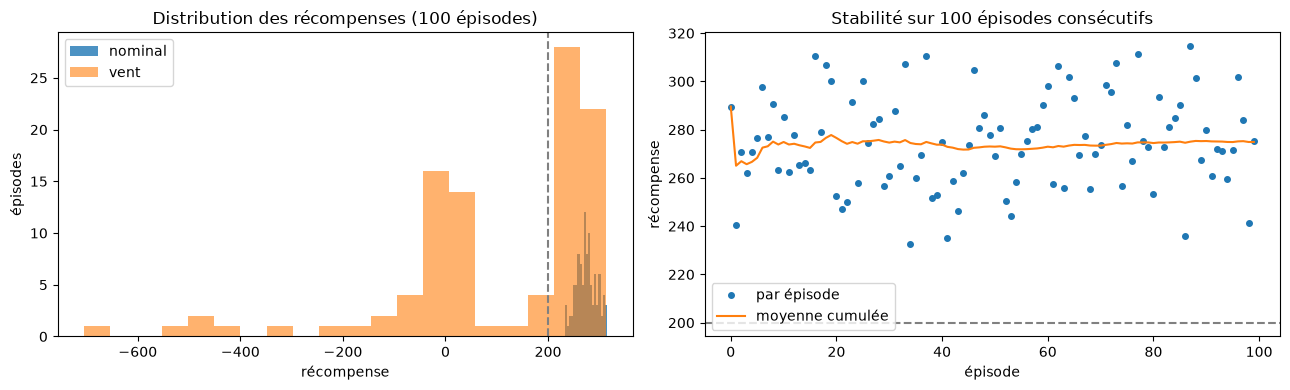

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(final_rewards, bins=20, alpha=0.8, label="nominal")
axes[0].hist(wind_rewards, bins=20, alpha=0.6, label="vent")
axes[0].axvline(200, ls="--", c="gray"); axes[0].set_xlabel("récompense"); axes[0].set_ylabel("épisodes")
axes[0].set_title("Distribution des récompenses (100 épisodes)"); axes[0].legend()
axes[1].plot(final_rewards, "o", ms=4, label="par épisode")
axes[1].plot(pd.Series(final_rewards).expanding().mean(), label="moyenne cumulée")
axes[1].axhline(200, ls="--", c="gray"); axes[1].set_xlabel("épisode"); axes[1].set_ylabel("récompense")
axes[1].set_title("Stabilité sur 100 épisodes consécutifs"); axes[1].legend()
plt.tight_layout(); plt.show()

### Précision et carburant : analyse des parties

In [12]:
games = [play_episode(model, seed=20_000 + i) for i in range(100)]
games_df = pd.DataFrame([{k: g[k] for k in ("total_reward", "n_steps", "outcome", "fuel", "main_engine", "side_engine")}
                         | {"x_final": g["steps"]["x"].iloc[-1]} for g in games])
display(games_df["outcome"].value_counts().to_frame("parties"))
display(games_df.describe().loc[["mean", "std", "min", "max"]])
print(f"Précision : |x| final moyen = {games_df['x_final'].abs().mean():.3f} "
      f"(la zone cible s'étend de -0.2 à +0.2) ; {(games_df['x_final'].abs() < 0.2).mean():.0%} des poses dans la zone.")

,parties
outcome,
atterrissage,100


,total_reward,n_steps,fuel,main_engine,side_engine,x_final
mean,279.4,248.8,32.5,105.6,27.0,-7.1e-03
std,20.4,15.7,1.3,3.9,11.3,3.1e-02
min,228.4,218.0,29.8,96.0,4.0,-8.7e-02
max,319.0,288.0,35.9,116.0,57.0,7.1e-02


Précision : |x| final moyen = 0.025 (la zone cible s'étend de -0.2 à +0.2) ; 100% des poses dans la zone.


**Analyse de l'évaluation finale.**

- **Critère atteint avec marge** : ≈ 275 ± 19 sur 100 épisodes jamais vus, pire épisode ≈ 233, **100 %** des
  épisodes au-dessus de 200. La moyenne cumulée se stabilise dès une vingtaine d'épisodes : la mesure est fiable.
- **Précision** : position horizontale finale moyenne |x| ≈ 0.025 alors que la zone cible s'étend de −0.2 à +0.2 ;
  les 100 poses sont dans la zone.
- **Carburant** : ≈ 32 unités de pénalité par atterrissage (≈ 106 pas de moteur principal, ≈ 27 de moteurs
  latéraux) pour ≈ 5 s de vol. L'agent coupe les moteurs une fois posé : la récompense pénalise chaque goutte.
- **Généralisation** : sur de nouveaux terrains et positions de départ, aucune dégradation (≈ 275 contre ≈ 280 à
  l'entraînement). En revanche, **avec vent et turbulences** — une physique jamais vue — la moyenne tombe à
  ≈ 100 et un épisode sur deux échoue : le modèle n'a pas appris à compenser une poussée latérale extérieure.

### Robustesse : toutes les expériences face au vent

Chaque modèle a aussi été évalué sur 100 épisodes **avec vent et turbulences** (`python -m eagle1.train --wind-eval`).
Une dernière expérience, `ppo_final_wind`, reprend la configuration finale mais **s'entraîne avec du vent**
(randomisation de l'environnement).

,algo,changed,timesteps,mean_reward,success_rate,wind_mean_reward,wind_success_rate
name,,,,,,,
ppo_ent_0.01,PPO,ent_coef=0.01,1000000,273.2,94%,206.6,76%
ppo_gae_0.98,PPO,gae_lambda=0.98,1000000,267.1,95%,201.1,77%
ppo_lr_1e-3,PPO,learning_rate=1e-3,1000000,280.5,100%,195.9,72%
ppo_baseline,PPO,défaut SB3,1000000,222.2,88%,139.4,56%
ppo_nsteps_1024,PPO,n_steps=1024,1000000,190.6,77%,131.7,45%
ppo_final_wind,PPO,entraînement avec vent,2000000,201.0,77%,125.1,42%
ppo_final_s0,PPO,combinaison finale,2000000,280.5,100%,122.6,56%
ppo_final_s1,PPO,combinaison finale,2000000,282.3,100%,120.5,61%
ppo_epochs_4,PPO,n_epochs=4,1000000,176.6,67%,113.8,39%


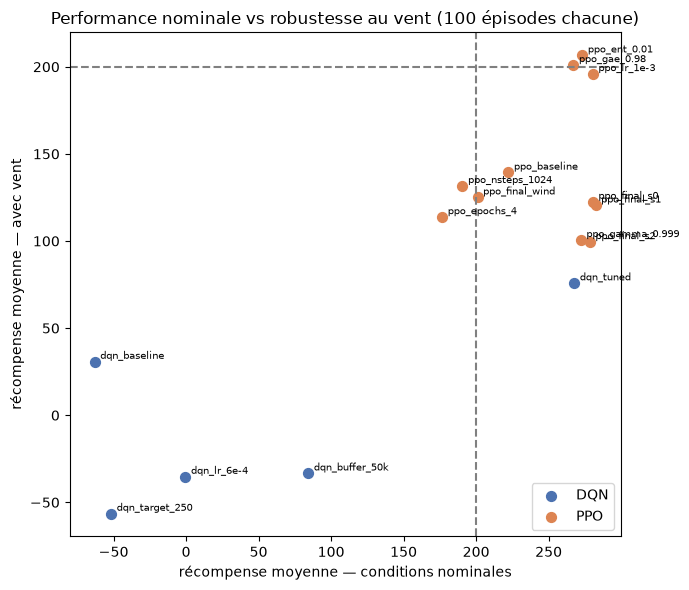

In [13]:
rob = load_experiments().set_index("name")[["algo", "changed", "timesteps", "mean_reward", "success_rate",
                                            "wind_mean_reward", "wind_success_rate"]]
display(show(rob.sort_values("wind_mean_reward", ascending=False)))

fig, ax = plt.subplots(figsize=(7, 6))
for algo, color in (("DQN", "#4C72B0"), ("PPO", "#DD8452")):
    sub = rob[rob["algo"] == algo]
    ax.scatter(sub["mean_reward"], sub["wind_mean_reward"], c=color, label=algo, s=50)
    for name, row in sub.iterrows():
        ax.annotate(name, (row["mean_reward"], row["wind_mean_reward"]), fontsize=7, xytext=(4, 2),
                    textcoords="offset points")
ax.axvline(200, ls="--", c="gray"); ax.axhline(200, ls="--", c="gray")
ax.set_xlabel("récompense moyenne — conditions nominales"); ax.set_ylabel("récompense moyenne — avec vent")
ax.set_title("Performance nominale vs robustesse au vent (100 épisodes chacune)"); ax.legend()
plt.tight_layout(); plt.show()

**Analyse de la robustesse.**

- **Performance nominale ≠ robustesse.** Le modèle de production (≈ 280 en nominal) ne fait que ≈ 120 avec vent.
  Les variantes PPO entraînées 1 M de pas avec `ent_coef=0.01`, `gae_lambda=0.98` ou `learning_rate=1e-3`
  tiennent ≈ 200 avec vent (≈ 75 % de réussite) : un entraînement plus long **spécialise** la politique sur les
  conditions vues. C'est une forme de surapprentissage à l'environnement, invisible si l'on n'évalue qu'en nominal.
- **DQN est le moins robuste** : même réglé, il chute à ≈ 76 avec vent.
- **Entraîner avec du vent n'a pas suffi** : `ppo_final_wind` obtient ≈ 201 ± 61 en nominal et ≈ 125 avec vent
  (42 % de réussite). Avec le même budget de 2 M de pas, la tâche bruitée est plus difficile à apprendre : il
  faudrait davantage de pas, ou partir d'une configuration plus exploratoire (`ent_coef`).

**Décision** : le cahier des charges porte sur l'environnement nominal ; le modèle **`ppo_final_s0`** reste en
production. La robustesse au vent est la principale piste d'amélioration (voir conclusion).

## 7. Vidéo de démonstration

Générée par [`eagle1/video.py`](../eagle1/video.py) avec `gymnasium.wrappers.RecordVideo` : 25 s
d'atterrissages consécutifs (`python -m eagle1.video`).

In [14]:
Video("../media/eagle1_atterrissage.mp4", width=600)

## 8. Mise à disposition : API, GUI et tableau de bord

```
 GUI (Streamlit :8501)  ─┐                      ┌─ modèle models/eagle1_best.zip
                          ├── HTTP ──▶  API FastAPI (:8000) ──┤
 Tableau de bord (:8502) ─┘                      └─ parties enregistrées results/eagle1.db
```

**Toute la logique RL est dans l'API** ([`eagle1/api.py`](../eagle1/api.py)) ; le GUI et le tableau de bord
ne font qu'afficher. Lancement de tout le prototype local : `docker compose up -d`.

| Endpoint | Rôle |
|---|---|
| `POST /play` | reçoit un état (8 réels), renvoie l'action et les probabilités de chaque action |
| `POST /episode` | joue une partie complète : résumé, télémétrie pas à pas, animation GIF |
| `POST /evaluate` | joue N parties et renvoie moyenne, écart-type, taux de réussite |
| `GET /episodes`, `/decisions` | historique des parties et des décisions (tableau de bord) |
| `GET /experiments`, `/experiments/curves` | résultats d'entraînement |

- **GUI** ([`eagle1/gui.py`](../eagle1/gui.py), http://localhost:8501) : lance une partie, affiche l'animation,
  la récompense, l'issue, le carburant, la télémétrie et la séquence d'actions.
- **Tableau de bord** ([`eagle1/dashboard.py`](../eagle1/dashboard.py), http://localhost:8502) : récompenses par
  partie (moyenne, écart-type, taux de réussite), décisions de l'IA selon la circonstance (phase de vol,
  inclinaison, position, vitesse), comparaison des expériences et courbes d'apprentissage.

Démonstration de l'API sans serveur, avec le client de test FastAPI :

In [15]:
from fastapi.testclient import TestClient
import eagle1.core as core
core.DB_PATH = core.RESULTS / "notebook_demo.db"      # ne pollue pas la base du tableau de bord
from eagle1.api import app

with TestClient(app) as client:
    print(client.get("/health").json())
    for state in ([0, 1.4, 0, -0.2, 0, 0, 0, 0], [0, 0.5, 0, -1.0, 0, 0, 0, 0], [0, 0.6, 0, -0.1, 0.3, 0.2, 0, 0]):
        print(state, "->", client.post("/play", json={"state": state}).json())
    ep = client.post("/episode", json={"seed": 7, "render": False}).json()
    print({k: ep[k] for k in ("seed", "total_reward", "n_steps", "outcome", "fuel")})
core.DB_PATH.unlink(missing_ok=True)

/opt/venv/lib/python3.11/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


{'status': 'ok', 'model_loaded': True}
[0, 1.4, 0, -0.2, 0, 0, 0, 0] -> {'action': 3, 'action_name': 'Moteur droit', 'scores': {'Rien': 0.3102, 'Moteur gauche': 0.2928, 'Moteur principal': 0.0, 'Moteur droit': 0.397}}
[0, 0.5, 0, -1.0, 0, 0, 0, 0] -> {'action': 2, 'action_name': 'Moteur principal', 'scores': {'Rien': 0.0, 'Moteur gauche': 0.0, 'Moteur principal': 1.0, 'Moteur droit': 0.0}}
[0, 0.6, 0, -0.1, 0.3, 0.2, 0, 0] -> {'action': 3, 'action_name': 'Moteur droit', 'scores': {'Rien': 0.0005, 'Moteur gauche': 0.0, 'Moteur principal': 0.0, 'Moteur droit': 0.9995}}


{'seed': 7, 'total_reward': 268.96326529065954, 'n_steps': 254, 'outcome': 'atterrissage', 'fuel': 32.19}


## 9. Conclusion

| Exigence | Résultat |
|---|---|
| Moyenne ≥ 200 sur 100 épisodes, stable | ✅ ≈ 275 ± 19, 100 % ≥ 200, pire épisode ≈ 233 |
| Reproductibilité | ✅ 3 graines à ≈ 280 (écart 1.6) |
| Précision et carburant | ✅ 100 % des poses dans la zone, ≈ 32 unités de carburant par atterrissage |
| Démarche documentée | ✅ baselines, 12 expériences « un paramètre à la fois », TensorBoard, configuration finale |
| Livrables | ✅ notebook, vidéo 25 s, API, GUI, tableau de bord, tests, CI |

**Ce qu'il faut retenir**

1. **Le choix de l'algorithme compte** : PPO converge de façon fiable ; DQN par défaut se bloque dans un
   comportement de « vol stationnaire » et n'atteint le seuil qu'après un réglage complet.
2. **Les hyperparamètres comptent autant que l'algorithme** : `learning_rate`, `gamma`, `ent_coef`, `gae_lambda`
   font passer PPO de 222 ± 73 à ≈ 280 ± 20.
3. **Une bonne évaluation est exigeante** : graines jamais vues, 100 épisodes, plusieurs graines d'entraînement,
   et un test hors distribution (vent) qui révèle une limite qu'une moyenne nominale cache.

**Pistes d'amélioration** : entraînement avec vent sur un budget plus long ou à partir d'une configuration plus
exploratoire ; recherche d'hyperparamètres automatisée (Optuna) avec plusieurs graines par essai ; version à
poussée continue (`LunarLanderContinuous-v3`) pour doser la poussée et économiser davantage de carburant.